# Task 2 — Detector Response Analysis

**Data generation**

The analysis uses 50,000 events generated with the `full` preset and random seed 5:

```bash
flashsim generate -n 50000 --seed 5 -o data/t2_full.h5
```

The notebook can be run from either the repository root or the `notebooks` directory.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from prob_reco_sbi.flash import load, network_input

# Load the simulation data
path = Path("data/t2_full.h5")
if not path.exists():
    path = Path("../data/t2_full.h5")
data = load(path)

# True event parameters
E = data.truth.energy
x0 = data.truth.x
y0 = data.truth.y
r0 = np.hypot(x0, y0)

# Sensor observations
charge = data.response.charge
time_mean = data.response.time_mean
time_first = data.response.time_first

# Basic quantities
R = data.detector.radius
N, M = charge.shape
Q = charge.sum(axis=1)
Y = data.config.optics.light_yield

print("Events:", N)
print("Sensors:", M)
print("Charge shape:", charge.shape)
print("Mean time shape:", time_mean.shape)

Events: 50000
Sensors: 32
Charge shape: (50000, 32)
Mean time shape: (50000, 32)


**Binned statistics:** The helper below calculates the mean and standard error of a measured quantity within bins of another variable. These summaries are used to study energy- and radius-dependent trends.

In [14]:
def plot_binned(ax, x, y, bins):          #将数据按照 x 分成若干区间，计算每个区间内 y 的平均值和统计误差，最后绘制带误差棒的曲线。
    centers = 0.5 * (bins[:-1] + bins[1:])#计算每个区间的中心点
    indices = np.digitize(x, bins) - 1    #np.digitize() 可以判断数组里的每个值属于哪个区间
    indices[x == bins[-1]] = len(centers) - 1
    means = []
    errors = []
    for i in range(len(centers)):
        values = y[(indices == i) & np.isfinite(y)] #这里是按照 x 进行分箱，对 有限值的y 进行统计。
        if len(values) > 1:
            means.append(np.mean(values)) #计算平均值并存入means
            errors.append(
                np.std(values, ddof=1) / np.sqrt(len(values))
            )                            #计算标准差并存入errors
        else:
            means.append(np.nan)
            errors.append(np.nan)
    ax.errorbar(
        centers, means, yerr=errors,
        fmt="o-", capsize=3
    )#这个函数将平均值和误差棒一起画出来
    #centers：横坐标为每个分箱的中心 #means：纵坐标为每个分箱的平均值 #yerr=errors：纵向误差棒的长度 #fmt="o-"：用圆点表示数据，并用线连接#capsize=3误差棒两端横线的大小
    ax.grid(alpha=0.25)

## T2.1 — Sensor Charge Distributions

**Question:** How are sensor charges and hit-sensor counts distributed? How does the fraction of empty sensors depend on energy $E$ and vertex radius $r_0$?

We examine individual sensor charges and the number of sensors with at least one hit per event. Binned means and standard errors are used to compare the empty-sensor fraction across energy and radius.

In [15]:
all_charges = charge.ravel() # All sensor charges #展平成一维数组
hit = charge > 0  # Define the hit mask before its first use
n_hit = hit.sum(axis=1) # 每个事件有多少传感器收到了事件 #计算第一个维度的平均值
f_empty = (charge == 0).mean(axis=1) # 每个事件中空传感器所占的比例

print(all_charges.shape)
print(n_hit.shape)
print(f_empty.shape)

(1600000,)
(50000,)
(50000,)


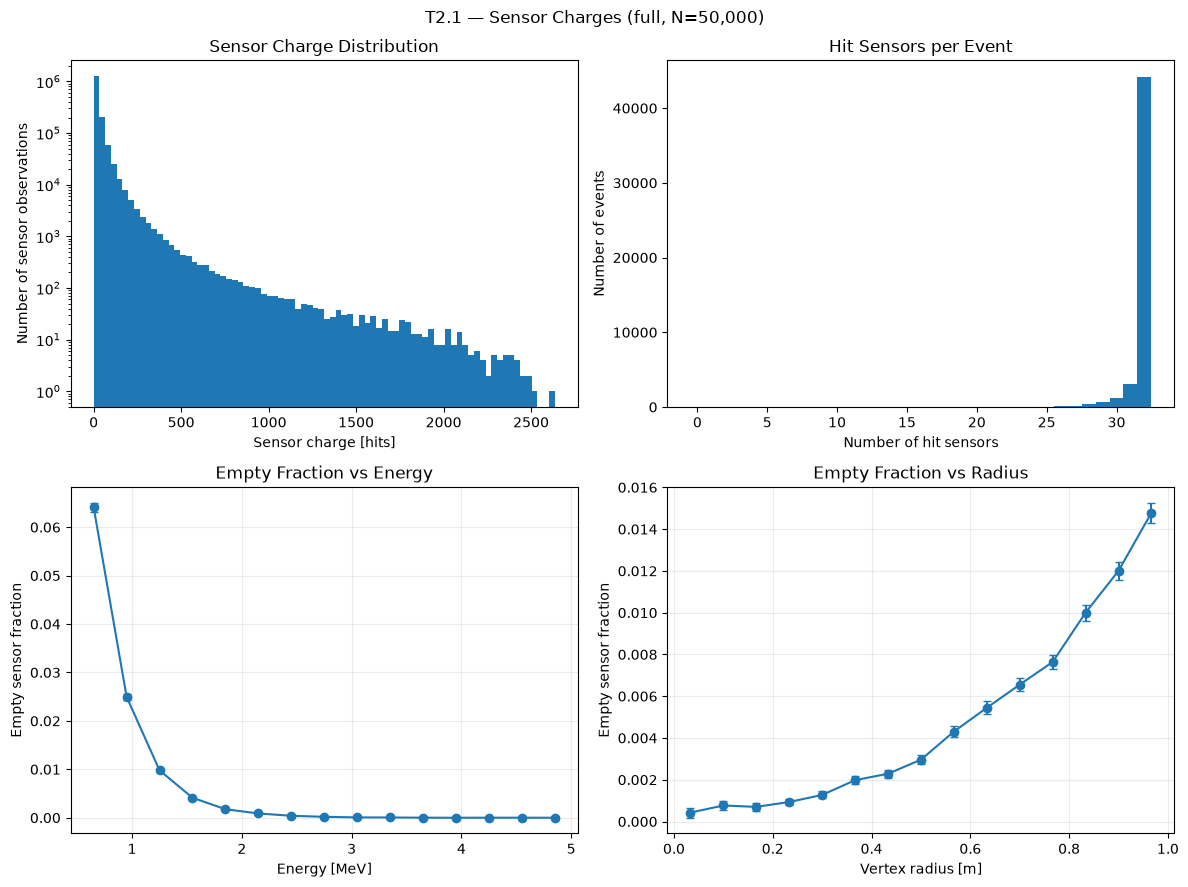

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))

# 1. Distribution of sensor charges
ax[0, 0].hist(all_charges, bins=80, log=True)  #绘制直方图，bins=80 表示将数据的范围分成 80 个区间，统计每个区间内有多少。
ax[0, 0].set(
    xlabel="Sensor charge [hits]",
    ylabel="Number of sensor observations",
    title="Sensor Charge Distribution"
)
# 2. Number of hit sensors per event
ax[0, 1].hist(
    n_hit,
    bins=np.arange(-0.5, M + 1.5)
)
ax[0, 1].set(
    xlabel="Number of hit sensors",
    ylabel="Number of events",
    title="Hit Sensors per Event"
)
# 3. Empty fraction vs energy
plot_binned(
    ax[1, 0],
    E,
    f_empty,
    np.linspace(E.min(), E.max(), 16)
)
ax[1, 0].set(
    xlabel="Energy [MeV]",
    ylabel="Empty sensor fraction",
    title="Empty Fraction vs Energy"
)

# 4. Empty fraction vs vertex radius
plot_binned(
    ax[1, 1],
    r0,
    f_empty,
    np.linspace(0, R, 16)
)
ax[1, 1].set(
    xlabel="Vertex radius [m]",
    ylabel="Empty sensor fraction",
    title="Empty Fraction vs Radius"
)

fig.suptitle(f"T2.1 — Sensor Charges (full, N={N:,})")
plt.tight_layout()
plt.savefig("T2.1_sensor_charges.png", dpi=200)
plt.show()

**Observation:** Most events register hits in nearly all 32 sensors, while the individual-sensor charge distribution is concentrated at low values. The empty-sensor fraction falls rapidly as energy increases and rises towards the detector boundary. This indicates that both light yield and event position affect which sensors record a signal.

## T2.2 — Total Charge and Light Collection

**Question:** What is the distribution of total charge $Q$, how does $Q$ depend on energy $E$, and how does the light collection $Q/(YE)$ vary with vertex radius $r_0$?

We sum the charges over all sensors and normalize the detected charge by the mean emitted photon number, $YE$.

In [17]:
light_collection = Q / (Y * E)

print("Mean total charge:", Q.mean())
print("Mean light collection:", light_collection.mean())

Mean total charge: 893.02686
Mean light collection: 0.32576458537416547


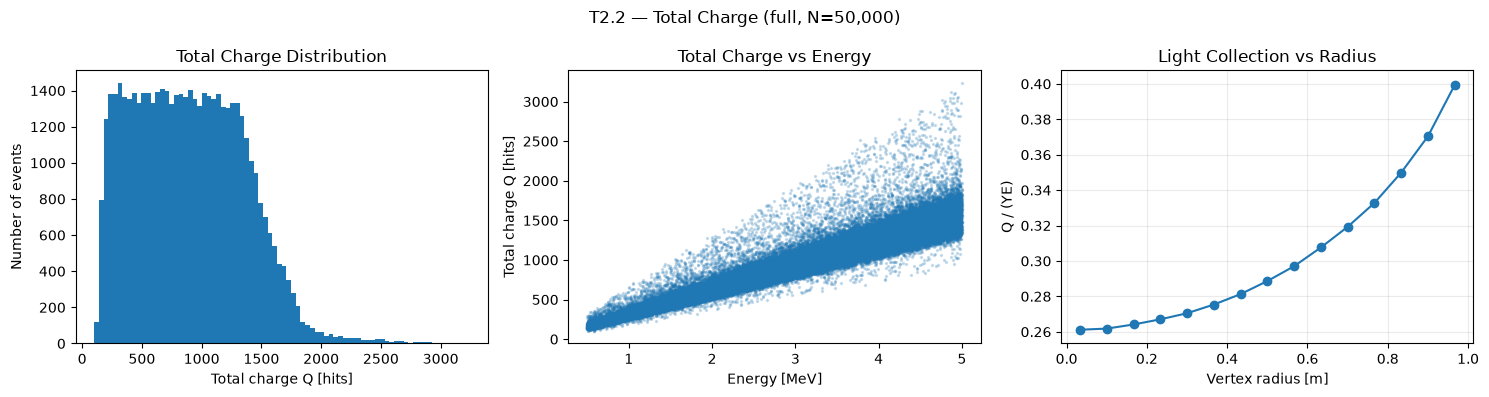

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# 1. Total charge distribution
ax[0].hist(Q, bins=80)
ax[0].set(
    xlabel="Total charge Q [hits]",
    ylabel="Number of events",
    title="Total Charge Distribution"
)
# 2. Total charge vs energy
ax[1].scatter(E, Q, s=2, alpha=0.2)
ax[1].set(
    xlabel="Energy [MeV]",
    ylabel="Total charge Q [hits]",
    title="Total Charge vs Energy"
)
# 3. Light collection vs radius
plot_binned(
    ax[2],
    r0,
    light_collection,
    np.linspace(0, R, 16)
)
ax[2].set(
    xlabel="Vertex radius [m]",
    ylabel="Q / (YE)",
    title="Light Collection vs Radius"
)

fig.suptitle(f"T2.2 — Total Charge (full, N={N:,})")
plt.tight_layout()
plt.savefig("T2.2_total_charge.png", dpi=200)
plt.show()

**Observation:** The mean total charge is approximately 893 hits, and the mean light collection is 0.326. Total charge increases with deposited energy but has substantial event-to-event spread. Light collection rises from about 0.26 near the center to about 0.40 near the wall, showing a clear position dependence that can bias an energy estimate based only on $Q$.

## T2.3 — Sensor Hit Times

**Question:** How do mean hit times, first-hit times, and relative mean times differ?

We use only sensors with detected photons because empty sensors have undefined raw hit times. Relative times are obtained by subtracting the charge-weighted mean time of each event, removing its common time offset.

In [19]:
hit = charge > 0

valid_mean_times = time_mean[hit]
valid_first_times = time_first[hit]

In [20]:
X = network_input(charge, time_mean)#charge转换成log，tm转换成 relative time
relative_times = X[:, M:] #对NumPy 数组切片，选择32后面的所有列
log_charges = X[:, :M]

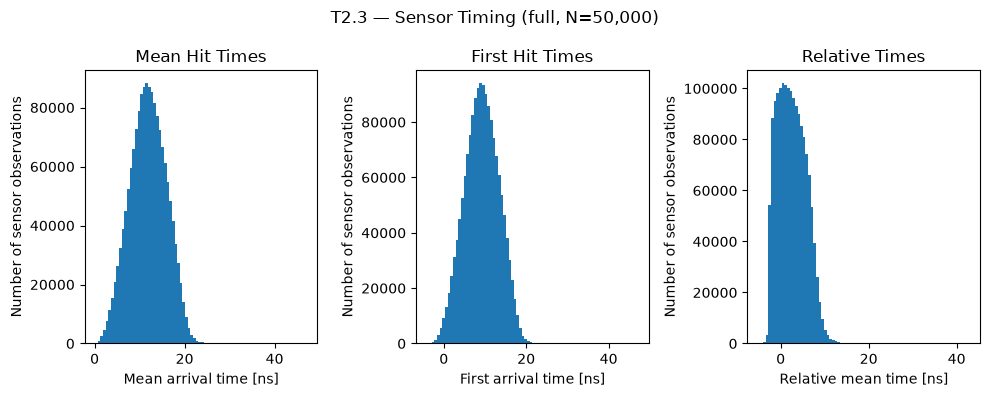

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(10, 4))
# Mean arrival times
ax[0].hist(time_mean[hit], bins=80) #绘制直方图，bins=80 表示将时间数据的范围分成 80 个区间，统计每个区间内有多少个传感器观测。
ax[0].set(
    xlabel="Mean arrival time [ns]",
    ylabel="Number of sensor observations",
    title="Mean Hit Times"
)
# First arrival times
ax[1].hist(time_first[hit], bins=80)
ax[1].set(
    xlabel="First arrival time [ns]",
    ylabel="Number of sensor observations",
    title="First Hit Times"
)
# Relative times
ax[2].hist(relative_times[hit], bins=80)
ax[2].set(
    xlabel="Relative mean time [ns]",
    ylabel="Number of sensor observations",
    title="Relative Times"
)

fig.suptitle(f"T2.3 — Sensor Timing (full, N={N:,})")
plt.tight_layout()
plt.savefig("T2.3_hit_times.png", dpi=200)
plt.show()

**Observation:** First-hit times are shifted towards earlier arrival times compared with mean hit times, as expected when the earliest hit is selected. The relative-time distribution is centered near zero with a positive tail. Subtracting the per-event reference removes the unknown common start time while preserving differences between sensor arrival times.

## T2.4 — Network Input Features

**Question:** What do the log-charge and relative-time network inputs look like, and how is an empty sensor represented?

The network input contains 32 log charges, $\ln(1+n_j)$, followed by 32 relative mean times. We inspect the feature distributions and verify that the array contains no `NaN` values.

In [22]:
print("Input shape:", X.shape)
print("Log charge shape:", log_charges.shape)
print("Relative time shape:", relative_times.shape)
print("Number of NaNs:", np.isnan(X).sum())

Input shape: (50000, 64)
Log charge shape: (50000, 32)
Relative time shape: (50000, 32)
Number of NaNs: 0


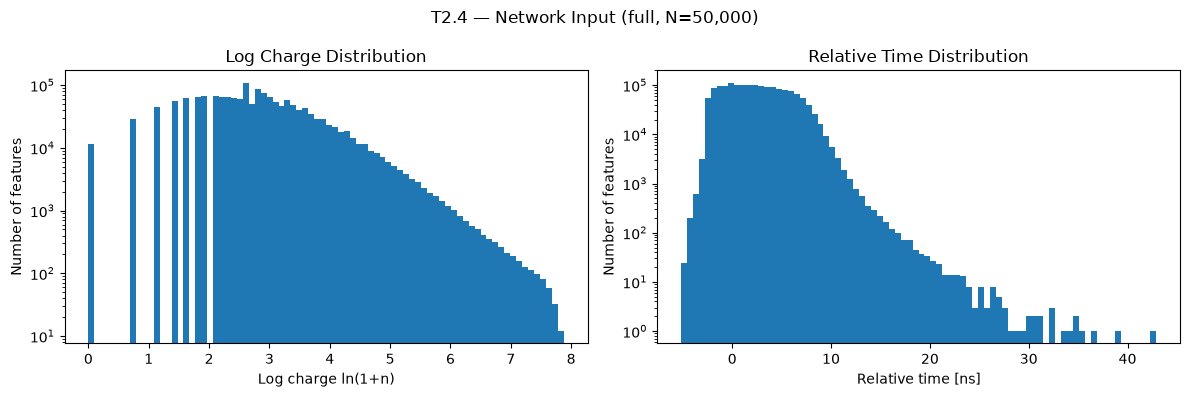

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Log charges
ax[0].hist(
    log_charges.ravel(),
    bins=80,
    log=True
)
ax[0].set(
    xlabel="Log charge ln(1+n)",
    ylabel="Number of features",
    title="Log Charge Distribution"
)
# Relative times
ax[1].hist(
    relative_times.ravel(),
    bins=80,
    log=True
)
ax[1].set(
    xlabel="Relative time [ns]",
    ylabel="Number of features",
    title="Relative Time Distribution"
)
fig.suptitle(f"T2.4 — Network Input (full, N={N:,})")
plt.tight_layout()
plt.savefig("T2.4_network_input.png", dpi=200)
plt.show()

**Observation:** The input has shape $(50{,}000,64)$, with no `NaN` values. The logarithmic transformation compresses large sensor charges, while relative times retain timing differences between sensors. Unlike the T2.3 timing plot, the network-input histogram includes zero values assigned to empty sensors; an empty sensor has both log charge and relative time equal to zero.

## T2.5 — Independent Investigations

**Question:** What additional information about photon transport and simple event reconstruction can be extracted from the simulated detector response?

Following the homework suggestion, I study three topics: the photon-fate composition as a function of radius, a naive vertex estimate from the charge-weighted barycentre, and a naive energy estimate from the total charge $Q$ with one global calibration constant.

### T2.5.1 — Photon-Fate Composition vs Radius

**Question:** How do the final photon-fate fractions vary with the true vertex radius $r_0$?

For each event, I compute the fractions of emitted photons that are detected, absorbed at the sensor, absorbed in the bulk medium, absorbed at the wall, or lost. I then average these fractions in bins of $r_0$ and display them as a stacked composition plot, so that the total height is one in every radius bin.

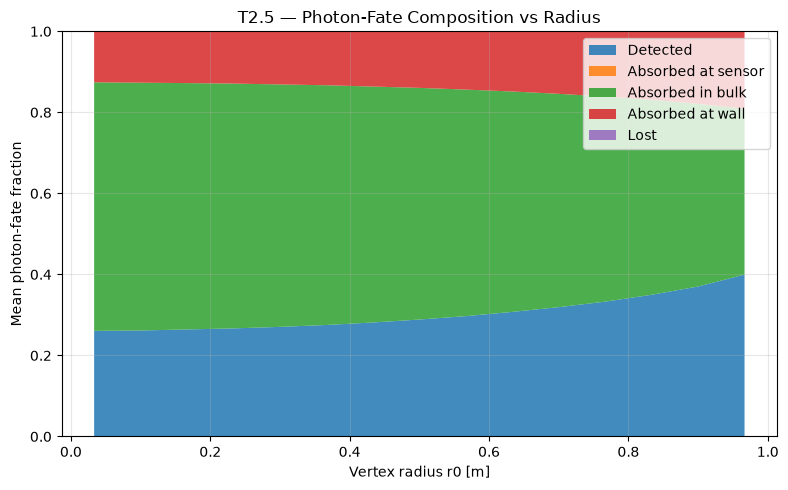

In [24]:
# Photon-fate counts
n_emitted = data.photons.n_emitted
n_detected = data.photons.n_detected
n_absorbed_sensor = data.photons.n_absorbed_sensor
n_absorbed_bulk = data.photons.n_absorbed_bulk
n_absorbed_wall = data.photons.n_absorbed_wall
n_lost = data.photons.n_lost

# Per-event fractions
f_detected = n_detected / n_emitted
f_sensor = n_absorbed_sensor / n_emitted
f_bulk = n_absorbed_bulk / n_emitted
f_wall = n_absorbed_wall / n_emitted
f_lost = n_lost / n_emitted

# Radius bins
r_edges = np.linspace(0, R, 16)
r_centers = 0.5 * (r_edges[:-1] + r_edges[1:])

def binned_mean(x, y, edges):
    means = []
    for i in range(len(edges) - 1):
        if i < len(edges) - 2:
            mask = (x >= edges[i]) & (x < edges[i + 1])
        else:
            mask = (x >= edges[i]) & (x <= edges[i + 1])
        values = y[mask]
        means.append(np.mean(values) if len(values) > 0 else np.nan)
    return np.array(means)

detected_mean = binned_mean(r0, f_detected, r_edges)
sensor_mean = binned_mean(r0, f_sensor, r_edges)
bulk_mean = binned_mean(r0, f_bulk, r_edges)
wall_mean = binned_mean(r0, f_wall, r_edges)
lost_mean = binned_mean(r0, f_lost, r_edges)

fig, ax = plt.subplots(figsize=(8, 5))

ax.stackplot(
    r_centers,
    detected_mean,
    sensor_mean,
    bulk_mean,
    wall_mean,
    lost_mean,
    labels=[
        "Detected",
        "Absorbed at sensor",
        "Absorbed in bulk",
        "Absorbed at wall",
        "Lost",
    ],
    alpha=0.85,
)

ax.set(
    xlabel="Vertex radius r0 [m]",
    ylabel="Mean photon-fate fraction",
    title="T2.5 — Photon-Fate Composition vs Radius",
)
ax.set_ylim(0, 1)
ax.legend(loc="upper right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("T2.5_photon_fate_composition_vs_radius.png", dpi=200)
plt.show()

**Observation:** The stacked plot shows how the final photon-fate composition changes with the event position. Because the fractions are normalized to the total number of emitted photons, the total height is one in every radius bin. The main point is to identify which fate dominates and how the detected fraction and the absorption channels change as the vertex moves towards the detector boundary.

### T2.5.2 — Naive Vertex Reconstruction

**Question:** How well can the charge-weighted barycentre estimate the true event vertex?

I define a naive position estimate by weighting each sensor position with its observed charge. This gives a simple barycentre estimator, which is then compared with the true coordinates and the true radius. I also study the position error as a function of $r_0$.

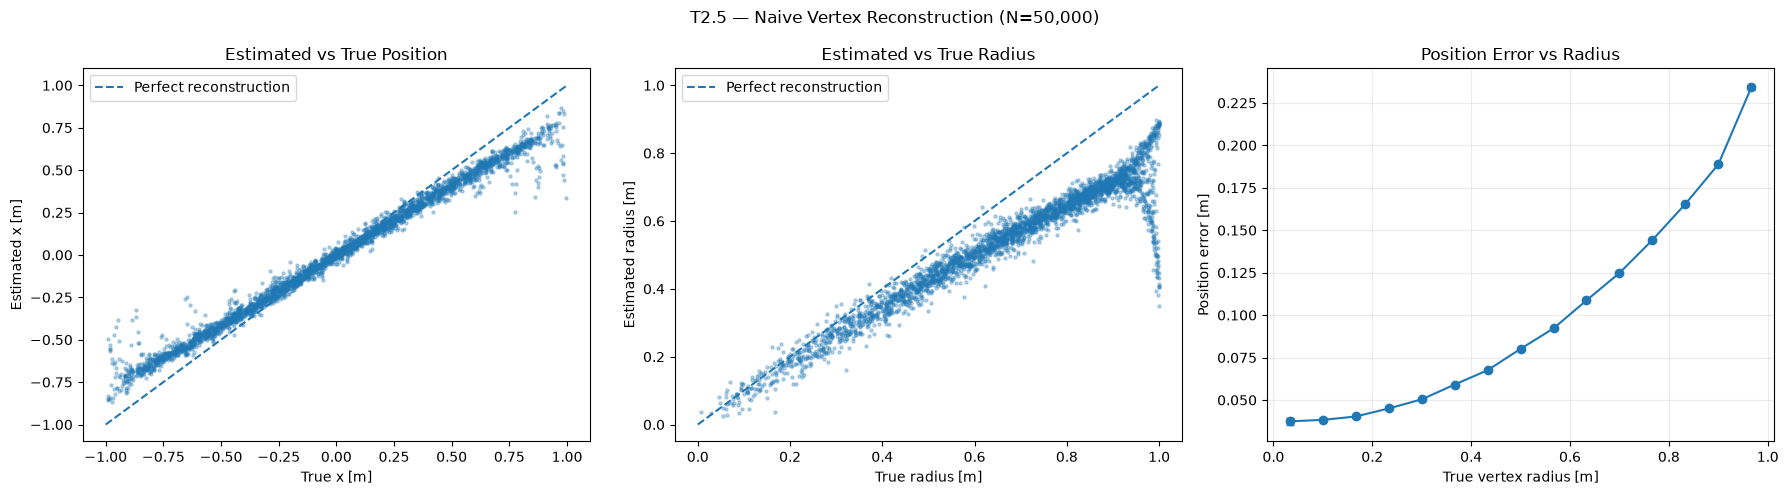

In [25]:
# Sensor coordinates on the detector boundary
if hasattr(data.detector, "x") and hasattr(data.detector, "y"):
    sx = np.asarray(data.detector.x)
    sy = np.asarray(data.detector.y)
elif hasattr(data.detector, "positions"):
    positions = np.asarray(data.detector.positions)
    sx, sy = positions[:, 0], positions[:, 1]
else:
    phi = np.linspace(0, 2 * np.pi, M, endpoint=False)
    sx = R * np.cos(phi)
    sy = R * np.sin(phi)

safe_Q = np.where(Q > 0, Q, np.nan)

x_est = (charge @ sx) / safe_Q
y_est = (charge @ sy) / safe_Q
r_est = np.hypot(x_est, y_est)
position_error = np.hypot(x_est - x0, y_est - y0)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Estimated x vs true x
step = max(1, N // 3000)
sample = np.arange(0, N, step)
ax[0].scatter(x0[sample], x_est[sample], s=5, alpha=0.3)
ax[0].plot([-R, R], [-R, R], "--", label="Perfect reconstruction")
ax[0].set(
    xlabel="True x [m]",
    ylabel="Estimated x [m]",
    title="Estimated vs True Position",
)
ax[0].legend()

# Estimated radius vs true radius
ax[1].scatter(r0[sample], r_est[sample], s=5, alpha=0.3)
ax[1].plot([0, R], [0, R], "--", label="Perfect reconstruction")
ax[1].set(
    xlabel="True radius [m]",
    ylabel="Estimated radius [m]",
    title="Estimated vs True Radius",
)
ax[1].legend()

# Position error vs radius
plot_binned(ax[2], r0, position_error, np.linspace(0, R, 16))
ax[2].set(
    xlabel="True vertex radius [m]",
    ylabel="Position error [m]",
    title="Position Error vs Radius",
)

fig.suptitle(f"T2.5 — Naive Vertex Reconstruction (N={N:,})")
plt.tight_layout()
plt.savefig("T2.5_naive_vertex.png", dpi=200)
plt.show()

**Observation:** The barycentre estimator provides a simple baseline for position reconstruction. The scatter plots show the degree to which the estimate follows the true coordinate and true radius, while the binned error plot reveals whether the reconstruction becomes systematically worse near the detector edge. Any visible bias reflects the limitations of using only charge information without an explicit optical model.

### T2.5.3 — Naive Energy Reconstruction

**Question:** Can a single calibration constant convert the total charge $Q$ into an estimate of the deposited energy, and is this estimate biased as a function of radius?

I define a global calibration constant $k$ through the median ratio $Q/E$ and reconstruct the energy as $E_{\mathrm{est}} = Q/k$. I then compare the reconstructed energy with the true energy and plot the mean relative bias $(E_{\mathrm{est}} - E)/E$ against $r_0$.

Calibration constant: 317.52 hits/MeV
Mean relative bias: 0.0260
Mean absolute relative error: 0.1270


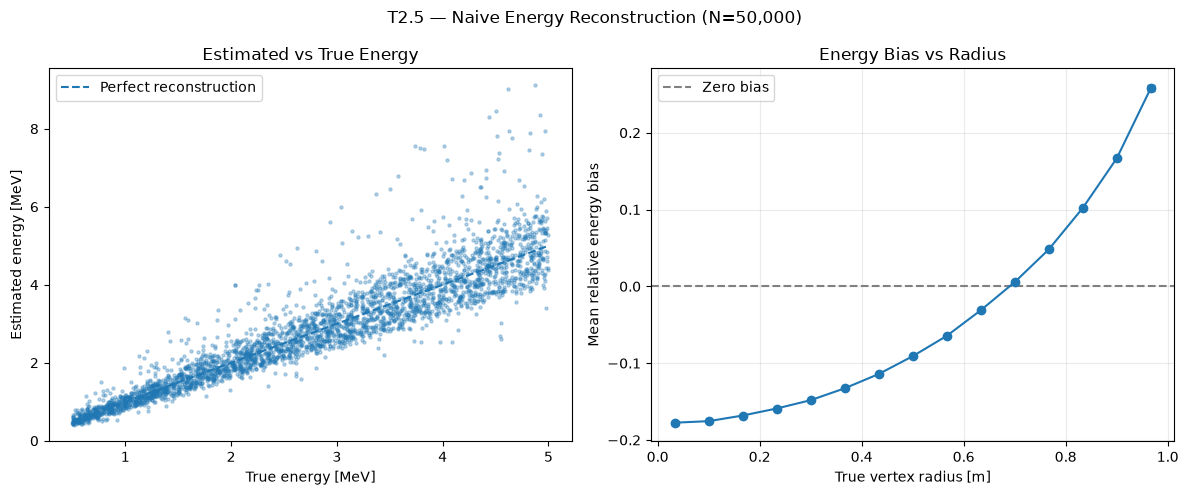

In [26]:
# One global calibration constant
k = np.median(Q / E)

# Reconstructed energy and relative bias
E_est = Q / k
energy_bias = (E_est - E) / E

print(f"Calibration constant: {k:.2f} hits/MeV")
print(f"Mean relative bias: {np.mean(energy_bias):.4f}")
print(f"Mean absolute relative error: {np.mean(np.abs(energy_bias)):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Estimated energy vs true energy
ax[0].scatter(E[sample], E_est[sample], s=5, alpha=0.3)
ax[0].plot(
    [E.min(), E.max()],
    [E.min(), E.max()],
    "--",
    label="Perfect reconstruction",
)
ax[0].set(
    xlabel="True energy [MeV]",
    ylabel="Estimated energy [MeV]",
    title="Estimated vs True Energy",
)
ax[0].legend()

# Energy bias vs radius
plot_binned(ax[1], r0, energy_bias, np.linspace(0, R, 16))
ax[1].axhline(0, color="gray", linestyle="--", label="Zero bias")
ax[1].set(
    xlabel="True vertex radius [m]",
    ylabel="Mean relative energy bias",
    title="Energy Bias vs Radius",
)
ax[1].legend()

fig.suptitle(f"T2.5 — Naive Energy Reconstruction (N={N:,})")
plt.tight_layout()
plt.savefig("T2.5_naive_energy.png", dpi=200)
plt.show()

**Observation:** The $E_{\mathrm{est}}$ versus $E$ scatter plot shows how well the total charge tracks the deposited energy with one global calibration constant. The second panel is the more important diagnostic: if the mean relative bias varies with $r_0$, then a single constant is not sufficient to remove the position dependence of light collection. This directly connects the energy bias to the radial trend already seen in the light-collection analysis of T2.2.